#**[개념]**

## **분류**

* 지도학습의 대표적인 유형
* 학습 데이터의 피처와 레이블값을 머신러닝 알고리즘으로 학습하여 모델 생성 -> 모델에 새로운 데이터 값 주어졌을 때 미지의 레이블 값 예측하는 것
* 다양한 머신러닝 알고리즘으로 구현 가능 *ex) 로지스틱 회귀, 결정 트리, 앙상블, 신경망 등*

---

*   지도학습: 명시적인 정답(레이블)이 있는 데이터가 주어진 상태에서 학습하는 머신러닝 방식

### **결정 트리**

* 데이터에 있는 규칙을 학습을 통해 자동으로 찾아내 트리 기반의 분류 규칙을 만드는 것
* 규칙 노드: 규칙 조건, 리프 노드: 결정된 클래스 값
* 새로운 규칙 조건마다 서브 트리 생성
* 최대한 균일한 데이터 세트를 구성할 수 있도록 트리를 분할해야 함

---

* 정보의 균일도를 측정하는 방법

(1) 엔트로피를 이용한 정보 이득

* 엔트로피: 주어진 데이터 집합의 혼잡도. 같은 값이 섞여 있으면 엔트로피가 낮음.
* 정보 이득 지수: 1 - (엔트로피 지수)
* 정보 이득 지수로 결정 트리가 분할 기준 결정 (정보 이득 높은 속성 기준 분할)

(2) 지니 계수

* 지니 계수가 낮을수록 데이터 균일도 높은 것으로 해석
* 지니 계수가 낮은 속성 기준 분할

---

**1. 결정 트리 모델의 특징**

(1) 장점

* 정보의 '균일도'를 기반으로 하고 있어서 쉽고 직관적
* 특별한 경우 제외하면 각 피처의 스케일링과 정규화 같은 전처리 작업 불필요 (정보의 균일도만 신경 쓰면 되기 때문)

(2) 단점
* 과적합으로 정확도가 떨어짐 => 트리의 크기를 사전에 제한하는 튜닝 필요

**2. 결정 트리 파라미터**

* 결정 트리 알고리즘을 구현한 DecisionTreeClassifier과 DecisionTreeRegressor 클래스에서 사용하는 하이퍼 파라미터

(1) min_samples_split
* 노드를 분할하기 위한 최소한의 샘플 데이터 수 (과적합 제어에 사용)
* 디폴트는 2. 작게 설정할수록 분할되는 노드가 많아져 과적합 가능성 증가

(2) min_samples_leaf
* 분할이 될 경우 왼쪽과 오른쪽의 브랜치 노드에서 가져야 할 최소한의 샘플 데이터 수 (과적합 제어에 사용)
* 큰 값으로 설정될수록 조건을 만족시키기 어려워 노드 분할 상대적으로 덜 수행
* 비대칭적 데이터의 경우 특정 클래스의 데이터가 극도로 작을 수 있으므로 작게 설정 필요

(3) max_features
* 최적의 분할을 위해 고려할 최대 피처 개수. 디폴트는 None(모든 피처 사용)
* int 형: 대상 피처의 개수, float 형: 전체 대비 대상 피처의 비율
* sqrt: 전체 피처 개수의 루트만큼 선정 (=auto)
* log: log2(전체 피처 개수) 선정

(4) max_depth
* 트리의 최대 깊이 규정. 디폴트는 None

(5) max_leaf_nodes
* 말단 노드(leaf)의 최대 개수

**3. 결정 트리 모델의 시각화 - export_graphviz()**

* 인자: 학습 완료된 Estimator, output 파일명, 결정 클래스 명칭, 피처 명칭
* export_graphviz(): Graphviz가 읽어 들여 그래프 형태로 시각화할 수 있는 출력 파일 생성
* export_graphviz()로 출력된 파일을 Graphviz의 파이썬 래퍼 모듈 호출해 시각적으로 표현 가능

@ DecisionTreeClassifier 객체의 feature_ importances _ 속성
* 피처의 중요한 역할 지표 제공
* 피처가 트리 분할 시 정보 이득 or 지니 계수를 얼마나 효율적으로 잘 개선시켰는지를 정규화된 값으로 표현 => 일반적으로 값이 높을수록 해당 피처의 중요도 높음
* ndarray 형태로 값 반환 & 피처 순서대로 값 할당
* 시각화 & 해당 속성을 통해 결정 트리 알고리즘을 직관적으로 이해 가능

**4. 결정 트리 과적합**

@ make_classification()
* 분류를 위한 테스트용 데이터를 쉽게 만들 수 있도록 제공된 함수
* 피처 데이터 세트 & 클래스 레이블 데이터 세트 반환

@ visualize_boundary()
* 머신러닝 모델이 클래스 값을 예측하는 결정 기준을 색상과 경계로 나타내는 함수
* 모델이 어떻게 데이터 세트를 예측, 분류하는지 이해 가능 -> 특성 이해 가능

#**[필사]**

In [1]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
import warnings
warnings.filterwarnings('ignore')

# DecisionTree Classifier 생성
dt_clf = DecisionTreeClassifier(random_state=156)

# 붓꽃 데이터를 로딩하고, 학습과 테스트 데이터 세트로 분리
iris_data = load_iris()
X_train, X_test, y_train, y_test = train_test_split(iris_data.data, iris_data.target, test_size=0.2, random_state=11)

# DecisionTreeClassifier 학습.
dt_clf.fit(X_train, y_train)

DecisionTreeClassifier(random_state=156)

In [2]:
from sklearn.tree import export_graphviz

# export_graphviz()의 호출 결과로 out_file로 지정된 tree.dot 파일을 생성함.
export_graphviz(dt_clf, out_file='tree.dot', class_names=iris_data.target_names, feature_names = iris_data.feature_names, impurity=True, filled=True)

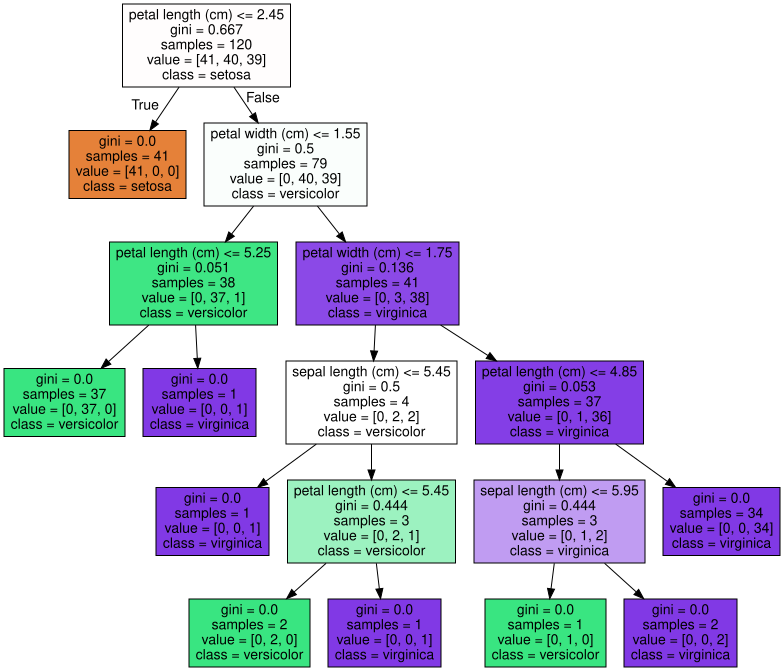

In [3]:
import graphviz
# 위에서 생성된 tree.dot 파일을 Graphviz가 읽어서 주피터 노트북상에서 시각화
with open("tree.dot") as f:
  dot_graph = f.read()
graphviz.Source(dot_graph)

1. 리프 노드
* 자식 노드가 없는 노드. 최종 클래스(레이블) 값이 결정됨.
* 오직 하나의 레이블 값으로 최종 데이터 구성 or 리프 노드가 될 수 있는 하이퍼 파라미터 조건 충족 시 리프노드
* *ex) 2번 노드(모든 데이터가 Setosa로 결정)*

2. 브랜치 노드
* 자식 노드가 있는 노드. 분할 규칙 조건을 가짐 for 자식 노드 생성
* *petal length <= 2.45* 와 같은 조건이 규칙 조건 (없으면 리프 노드)

---
노드 내에 기술된 지표의 의미

* gini: value=[]로 주어진 데이터 분포에서의 지니 계수
* samples: 현 규칙에 해당하는 데이터 건수
* value=[]: 클래스(레이블)값 기반 데이터 건수. *ex) value=[41,40,39]: 레이블 0인 값 41개, ...*
* 각 노드의 색깔: 붓꽃 데이터의 레이블 값을 의미. 주황(0), 초록(1), 보라(2)를 나타냄. 색깔 짙어질수록 지니 계수 낮고 해당 레이블에 속해는 샘플 데이터가 많다는 의미

---
노드별 설명

[1번 노드(루트 노드)]
* *class = setosa*: 하위 노드 가질 경우 setosa의 개수가 41개로 제일 많다는 뜻

[4번 노드]
* 38개의 샘플 데이터 중 Versicolor 37개, Virginica 1개
* 지니 계수 매우 낮으나 여전히 혼재 -> 새로운 규칙으로 다시 자식 노드 생성


Feature importances:
[0.025 0.    0.555 0.42 ]
sepal length (cm):0.025
sepal width (cm):0.000
petal length (cm):0.555
petal width (cm):0.420


<Axes: >

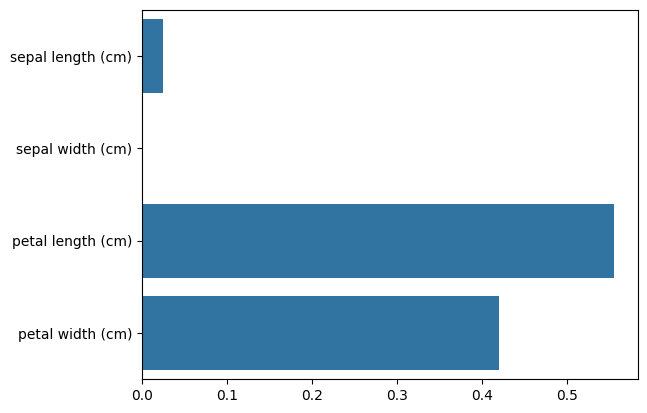

In [4]:
import seaborn as sns
import numpy as np
%matplotlib inline

# feature importance 추출
print("Feature importances:\n{0}".format(np.round(dt_clf.feature_importances_, 3)))

# feature별 importance 매핑
for name, value in zip(iris_data.feature_names, dt_clf.feature_importances_):
  print('{0}:{1:.3f}'.format(name, value))

# feature importance를 column 별로 시각화하기
sns.barplot(x=dt_clf.feature_importances_, y=iris_data.feature_names)

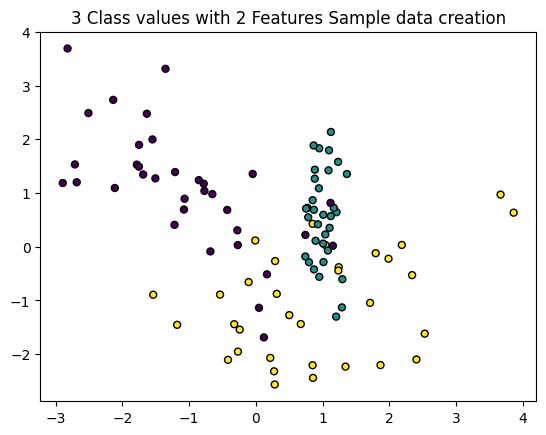

In [5]:
from sklearn.datasets import make_classification
import matplotlib.pyplot as plt
%matplotlib inline

plt.title("3 Class values with 2 Features Sample data creation")

# 2차원 시각화를 위해서 피처는 2개, 클래스는 3가지 유형의 분류 샘플 데이터 생성.
X_features, y_labels = make_classification(n_features=2, n_redundant=0, n_informative=2, n_classes=3, n_clusters_per_class=1, random_state=0)

# 그래프 형태로 2개의 피처로 2차원 좌표 시각화, 각 클래스 값은 다른 색깔로 표시됨.
plt.scatter(X_features[:, 0], X_features[:, 1], marker='o', c=y_labels, s=25, edgecolor='k')

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

def visualize_boundary(model, X, y):
  x_min, x_max = X[:,0].min() - 1, X[:,0].max() + 1
  y_min, y_max = X[:,0].min() - 1, X[:,1].max() + 1
  xx, yy = np.meshgrid(np.arange(x_min, x_max, 0.01), np.arange(y_min, y_max, 0.01))

  Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
  Z = Z.reshape(xx.shape)

  cmap_light = ListedColormap(['#FFAAAA', '#AAAAFF', '#AAFFAA'])
  cmap_bold = ListedColormap(['#FF0000', '#0000FF', '#00FF00'])

  plt.figure()
  plt.contourf(xx, yy, Z, cmap=cmap_light, alpha=0.8)
  plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cmap_bold, s=25, edgecolor='k')
  plt.xlim(xx.min(), xx.max())
  plt.ylim(yy.min(), yy.max())
  plt.title("Decision Boundary")
  plt.xlabel("Feature 1")
  plt.ylabel("Feature 2")
  plt.show()

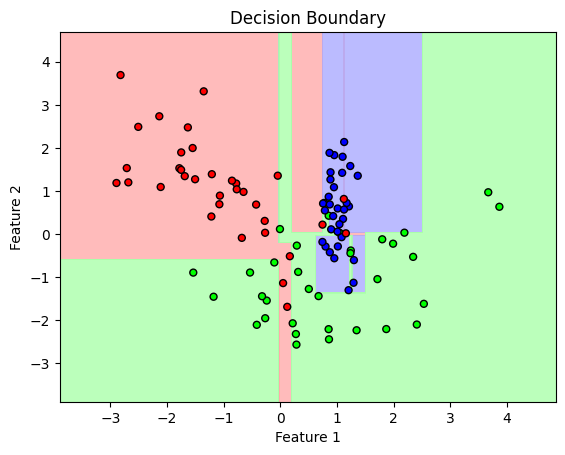

In [12]:
from sklearn.tree import DecisionTreeClassifier

# 특정한 트리 생성 제약 없는 결정 트리의 학습과 결정 경계 시각화.
dt_clf = DecisionTreeClassifier(random_state=156).fit(X_features, y_labels)
visualize_boundary(dt_clf, X_features, y_labels)

6개 이하의 데이터는 리프 노드 생성할 수 있도록 리프 노드 생성 규칙 완화: 예측 성능 더 뛰어날 가능성 높음

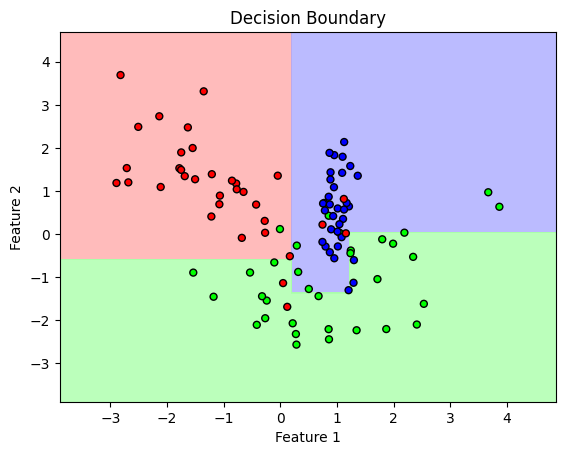

In [13]:
# min_samples_leaf=6으로 트리 생성 조건을 제약한 결정 경계 시각화
dt_clf = DecisionTreeClassifier(min_samples_leaf=6, random_state=156).fit(X_features, y_labels)
visualize_boundary(dt_clf, X_features, y_labels)

### 결정 트리 실습 - 사용자 행동 인식 데이터 세트

데이터: 30명에게 스마트폰 센서 장착한 뒤 사람의 동작과 관련된 여러 가지 피처를 수집한 데이터

In [14]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

# features.txt 파일에는 피처 이름 index와 피처명이 공백으로 분리되어 있음. 이를 DataFrame으로 로드.
feature_name_df = pd.read_csv('features.txt', sep='\s+', header=None, names=['column_index', 'column_name'])

# 피처명 index를 제거하고, 피처명만 리스트 객체로 생성한 뒤 샘플로 10개만 추출
feature_name = feature_name_df.iloc[:,1].values.tolist()
print('전체 피처명에서 10개만 추출:', feature_name[:10])

전체 피처명에서 10개만 추출: ['tBodyAcc-mean()-X', 'tBodyAcc-mean()-Y', 'tBodyAcc-mean()-Z', 'tBodyAcc-std()-X', 'tBodyAcc-std()-Y', 'tBodyAcc-std()-Z', 'tBodyAcc-mad()-X', 'tBodyAcc-mad()-Y', 'tBodyAcc-mad()-Z', 'tBodyAcc-max()-X']


인체의 움직임과 관련된 속성의 평균/표준편차가 X, Y, Z축 값으로 되어 있음을 유추 가능

In [15]:
feature_dup_df = feature_name_df.groupby('column_name').count()
print(feature_dup_df[feature_dup_df['column_index']>1].count())
feature_dup_df[feature_dup_df['column_index']>1].head()

column_index    42
dtype: int64


,column_index
column_name,
"fBodyAcc-bandsEnergy()-1,16",3
"fBodyAcc-bandsEnergy()-1,24",3
"fBodyAcc-bandsEnergy()-1,8",3
"fBodyAcc-bandsEnergy()-17,24",3
"fBodyAcc-bandsEnergy()-17,32",3


42개의 피처명 중복. 중복된 피처명에 대해 원본 피처명에 _1 or _2 추가 부여 (다음 코드)

In [18]:
def get_new_feature_name_df(old_feature_name_df):
  feature_dup_df = pd.DataFrame(data=old_feature_name_df.groupby('column_name').cumcount(), columns=['dup_cnt'])
  feature_dup_df = feature_dup_df.reset_index()
  new_feature_name_df = pd.merge(old_feature_name_df.reset_index(), feature_dup_df, how='outer')
  new_feature_name_df['column_name'] = new_feature_name_df[['column_name', 'dup_cnt']].apply(lambda x: x[0]+'_'+str(x[1]) if x[1]>0 else x[0], axis=1)
  new_feature_name_df = new_feature_name_df.drop(['index'], axis=1)
  return new_feature_name_df

In [19]:
import pandas as pd

def get_human_dataset():

  # 각 데이터 파일은 공백으로 분리되어 있으므로 read_csv에서 공백 문자를 sep으로 할당.
  feature_name_df = pd.read_csv('features.txt', sep='\s+', header=None, names=['column_index', 'column_name'])

  # 중복된 피처명을 수정하는 get_new_feature_name_df()를 이용, 신규 피처명 DataFrame 생성.
  new_feature_name_df = get_new_feature_name_df(feature_name_df)

  # DataFrame에 피처명을 칼럼으로 부여하기 위해 리스트 객체로 다시 변환
  feature_name = new_feature_name_df.iloc[:,1].values.tolist()

  # 학습 피처 데이터세트와 테스트 피처 데이터를 DataFrame으로 로딩. 칼럼명은 feature_name 적용
  X_train = pd.read_csv('X_train.txt', sep='\s+', names=feature_name)
  X_test = pd.read_csv('X_test.txt', sep='\s+', names=feature_name)

  # 학습 레이블과 테스트 레이블 데이터를 DataFrame으로 로딩하고 칼럼명은 action으로 부여
  y_train = pd.read_csv('y_train.txt', sep='\s+', header=None, names=['action'])
  y_test = pd.read_csv('y_test.txt', sep='\s+', header=None, names=['action'])

  # 로드된 학습/테스트용 DataFrame을 모두 반환
  return X_train, X_test, y_train, y_test

X_train, X_test, y_train, y_test = get_human_dataset()

In [20]:
print('## 학습 피처 데이터셋 info()')
print(X_train.info())

## 학습 피처 데이터셋 info()
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7352 entries, 0 to 7351
Columns: 561 entries, tBodyAcc-mean()-X to angle(Z,gravityMean)
dtypes: float64(561)
memory usage: 31.5 MB
None


7352개의 레코드로 561개의 피처를 갖고 있음

In [21]:
print(y_train['action'].value_counts())

action
6    1407
5    1374
4    1286
1    1226
2    1073
3     986
Name: count, dtype: int64


In [22]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

# 예제 반복 시마다 동일한 예측 결과 도출을 위해 random_state 설정
dt_clf = DecisionTreeClassifier(random_state=156)
dt_clf.fit(X_train, y_train)
pred = dt_clf.predict(X_test)
accuracy = accuracy_score(y_test, pred)
print('결정 트리 예측 정확도: {0:.4f}'.format(accuracy))

# DecisionTreeClassifier의 하이퍼 파라미터 추출
print('DecisionTreeClassifier 기본 하이퍼 파라미터:\n', dt_clf.get_params())

결정 트리 예측 정확도: 0.8548
DecisionTreeClassifier 기본 하이퍼 파라미터:
 {'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 156, 'splitter': 'best'}


In [23]:
from sklearn.model_selection import GridSearchCV

params = {'max_depth': [6, 8, 10, 12, 16, 20, 24], 'min_samples_split': [16]}

grid_cv = GridSearchCV(dt_clf, param_grid=params, scoring='accuracy', cv=5, verbose=1)
grid_cv.fit(X_train, y_train)
print('GridSearchCV 최고 평균 정확도 수치: {0:.4f}'.format(grid_cv.best_score_))
print('GridSearchCV 최적 하이퍼 파라미터:', grid_cv.best_params_)

Fitting 5 folds for each of 7 candidates, totalling 35 fits
GridSearchCV 최고 평균 정확도 수치: 0.8549
GridSearchCV 최적 하이퍼 파라미터: {'max_depth': 8, 'min_samples_split': 16}


학습 데이터를 5개로 나눠 검증한 교차 검증 평균 정확도

In [24]:
# GridSearchCV 객체의 cv_results_ 속성을 DataFrame으로 생성.
cv_results_df = pd.DataFrame(grid_cv.cv_results_)

# max_depth 파라미터 값과 그때의 테스트 세트, 학습 데이터 세트의 정확도 수치 추출
cv_results_df[['param_max_depth', 'mean_test_score']]

,param_max_depth,mean_test_score
0,6,0.847662
1,8,0.854879
2,10,0.852705
3,12,0.845768
4,16,0.847127
5,20,0.848624
6,24,0.848624


GridSearchCV 객체의 cv_results_ 속성: CV 세트에 하이퍼 파라미터를 순차적으로 입력했을 때의 성능 수치를 가짐

In [25]:
max_depths = [6, 8, 10, 12, 16, 20, 24]
# max_depths 값을 변화시키면서 그때마다 학습과 테스트 세트에서의 예측 성능 측정
for depth in max_depths:
  dt_clf = DecisionTreeClassifier(max_depth=depth, min_samples_split=16, random_state=156)
  dt_clf.fit(X_train, y_train)
  pred = dt_clf.predict(X_test)
  accuracy = accuracy_score(y_test, pred)
  print('max_depth = {0} 정확도: {1:.4f}'.format(depth, accuracy))

max_depth = 6 정확도: 0.8551
max_depth = 8 정확도: 0.8717
max_depth = 10 정확도: 0.8599
max_depth = 12 정확도: 0.8571
max_depth = 16 정확도: 0.8599
max_depth = 20 정확도: 0.8565
max_depth = 24 정확도: 0.8565


테스트 데이터로 실제 모델 평가해서 나온 정확도

In [26]:
params = {'max_depth': [8, 12, 16, 20], 'min_samples_split': [16, 24]}

grid_cv = GridSearchCV(dt_clf, param_grid=params, scoring='accuracy', cv=5, verbose=1)
grid_cv.fit(X_train, y_train)
print('GridSearchCV 최고 평균 정확도 수치: {0:.4f}'.format(grid_cv.best_score_))
print('GridSearchCV 최적 하이퍼 파라미터:', grid_cv.best_params_)

Fitting 5 folds for each of 8 candidates, totalling 40 fits
GridSearchCV 최고 평균 정확도 수치: 0.8549
GridSearchCV 최적 하이퍼 파라미터: {'max_depth': 8, 'min_samples_split': 16}


In [29]:
best_df_clf = grid_cv.best_estimator_
pred1 = best_df_clf.predict(X_test)
accuracy = accuracy_score(y_test, pred1)
print('결정 트리 예측 정확도:{0:.4f}'.format(accuracy))

결정 트리 예측 정확도:0.8717


GridSearchCV 객체인 grid_cv 속성인 best_estimator_는 최적 하이퍼 파라미터로 학습이 완료된 estimator 객체

---



결정 트리에서 각 피처의 중요도 확인

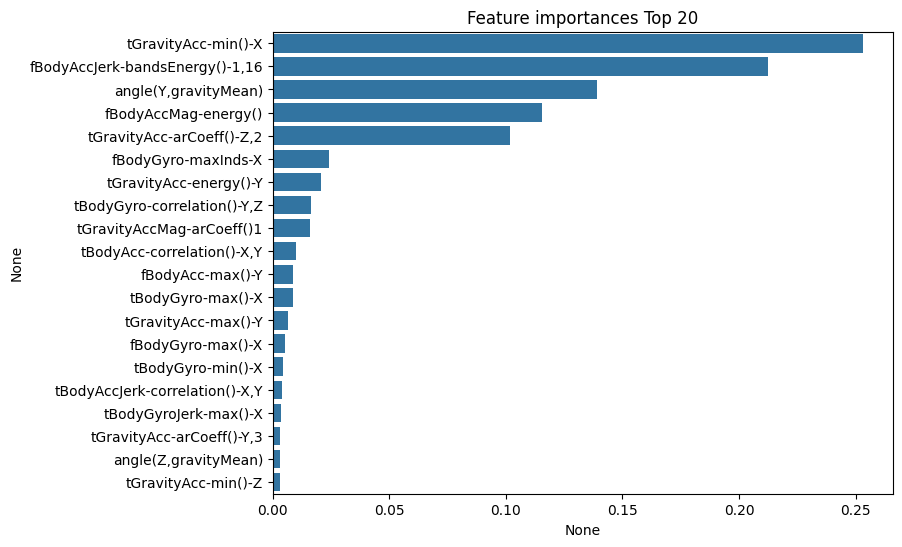

In [30]:
import seaborn as sns

ftr_importances_values = best_df_clf.feature_importances_
# Top 중요도로 정렬을 쉽게 하고, 시본(Seaborn)의 막대그래프로 쉽게 표현하기 위해 Series 변환
ftr_importances = pd.Series(ftr_importances_values, index=X_train.columns)
# 중요도값 순으로 Series를 정렬
ftr_top20 = ftr_importances.sort_values(ascending=False)[:20]
plt.figure(figsize=(8, 6))
plt.title('Feature importances Top 20')
sns.barplot(x=ftr_top20, y=ftr_top20.index)
plt.show()